# Notebook 1 — Data Quality, Cleaning, EDA & Feature Engineering
**Customer Response Prediction & Pricing Intelligence — Aurevia flu vaccines (CRISP-ML(Q))**

Follows the presented walkthrough:

| Walkthrough section | Where in this notebook |
|---|---|
| 2. Data overview & quality | Part 1 (checks) and Part 2 (cleaning) |
| 3. Exploratory analysis | Part 3 (3.1 – 3.7) |
| 4. Feature identification & selection | Part 4 (candidates + selection funnel steps 1–4; step 5 is in Notebook 2) |
| 5. Data preparation | Part 5 (construct, impute, standardise, save) |

**Output:** `data/processed/model_table.csv` — one row per account × product × season, same layout for history and 2025-26.

> Rule used everywhere: **only information known on the offer date may become a feature.**
> Scope note: the free-text call notes (`interaction_notes.csv`) and negotiation decks are **not used** in this version. Structured interactions are used for engagement features.

**Run tip:** use *Kernel → Restart Kernel and Run All Cells* — leftover variables from earlier runs can shadow names defined here.

Optional installs (skip if present): `%pip install pandas numpy matplotlib scikit-learn sweetviz`

In [4]:
import warnings; warnings.filterwarnings("ignore")
import re
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.max_columns", 80); pd.set_option("display.width", 220)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

RAW_DIR, INTERMEDIATE_DIR, PROCESSED_DIR = "../data/raw/", "../data/intermediate/", "../data/processed/"
WINDOW_DAYS  = 365          # look-back window before the offer date for interactions
RECENT_DAYS  = 90
HOLDOUT      = "2024-25"    # latest labelled season: kept as the final unseen test in Notebook 2
BLUE, GREY, RED = "#0b4a77", "#9aa5b1", "#c0392b"

contracts = pd.read_csv(RAW_DIR + "contracts_history.csv", parse_dates=["offer_date", "outcome_date"])
pred_set  = pd.read_csv(RAW_DIR + "contracts_prediction_set.csv", parse_dates=["offer_date", "outcome_date"])
customers = pd.read_csv(RAW_DIR + "customers.csv")
products  = pd.read_csv(RAW_DIR + "products.csv")
interactions     = pd.read_csv(RAW_DIR + "interactions.csv", parse_dates=["interaction_date"])
rounds    = pd.read_csv(RAW_DIR + "negotiation_rounds.csv")
decks     = pd.read_csv(RAW_DIR + "negotiation_decks.csv")
print(len(contracts), "history |", len(pred_set), "open 2025-26 |", len(customers), "customers |", len(interactions), "interactions")

1112 history | 430 open 2025-26 | 300 customers | 7809 interactions


# Part 1 — Data overview and quality verification  (walkthrough §2)
Each check is computed from the data, not typed in.

In [5]:
h = contracts.copy(); h["won"] = (h["outcome"] == "WON").astype(int)

# interactions after the decision: compare each interaction with the outcome date of that customer-season
ix = interactions.merge(h[["customer_id","season","outcome_date"]].drop_duplicates(["customer_id","season"]), on=["customer_id","season"])
after_decision = (ix["interaction_date"] > ix["outcome_date"]).mean()

# does negotiation_rounds reconcile with contracts?
rc = rounds.merge(h[["opportunity_id","customer_id","initial_offered_price_per_dose"]], on="opportunity_id", suffixes=("_round","_contract"))
cust_match = (rc["customer_id_round"] == rc["customer_id_contract"]).mean()

dup_names = customers["customer_name"].duplicated().sum()
checks = pd.DataFrame([
 ("Every history deal has an outcome",            f"{h['outcome'].notna().mean():.0%}",                     "OK"),
 ("Duplicate opportunity ids",                    int(contracts['opportunity_id'].duplicated().sum()),       "OK" if not contracts['opportunity_id'].duplicated().any() else "FIX"),
 ("Deals with unknown customer id",               int((~contracts['customer_id'].isin(customers['customer_id'])).sum()), "OK"),
 ("Deals with unknown product id",                int((~contracts['product_id'].isin(products['product_id'])).sum()),     "OK"),
 ("Customers with no buying group",               f"{customers['buying_group_id'].isna().mean():.0%}",       "Means 'not in a group' -> own category"),
 ("Final price present for WON / LOST deals",     f"{h.loc[h.won==1,'final_negotiated_price_per_dose'].notna().mean():.0%} / {h.loc[h.won==0,'final_negotiated_price_per_dose'].notna().mean():.0%}", "LEAKAGE: reveals outcome"),
 ("Win rate of deals with 5 negotiation rounds",  f"{h.loc[h.num_negotiation_rounds==5,'won'].mean():.0%} (n={(h.num_negotiation_rounds==5).sum()})", "LEAKAGE: known after negotiation"),
 ("Interactions dated AFTER the outcome",         f"{after_decision:.0%}",                                   "Filter by offer date"),
 ("Deals covered by negotiation decks",           f"{decks['opportunity_id'].nunique()/len(h):.0%}",          "Partial coverage"),
 ("2025-26 deals with a deck",                    int(decks['opportunity_id'].isin(pred_set['opportunity_id']).sum()), "Not available when scoring"),
 ("Negotiation rounds whose customer matches the contract", f"{cust_match:.0%}",                         "Does not reconcile -> exclude, raise with data owners"),
 ("Customer ids sharing a name with another id",  int(dup_names),                                           "Join on id, never on name"),
], columns=["check", "result", "verdict / impact"])
checks

,check,result,verdict / impact
0,Every history deal has an outcome,100%,OK
1,Duplicate opportunity ids,0,OK
2,Deals with unknown customer id,0,OK
3,Deals with unknown product id,0,OK
4,Customers with no buying group,52%,Means 'not in a group' -> own category
5,Final price present for WON / LOST deals,100% / 0%,LEAKAGE: reveals outcome
6,Win rate of deals with 5 negotiation rounds,100% (n=48),LEAKAGE: known after negotiation
7,Interactions dated AFTER the outcome,70%,Filter by offer date
8,Deals covered by negotiation decks,19%,Partial coverage
9,2025-26 deals with a deck,0,Not available when scoring


# Part 2 — Cleaning
* Stack history + 2025-26 into **one** table so both get identical feature treatment.
* Never impute the final price; it is excluded instead.

In [6]:
# ---- opportunities --------------------------------------------------------------------------
contracts["dataset"], pred_set["dataset"] = "history", "score"
opps = pd.concat([contracts, pred_set], ignore_index=True).drop_duplicates("opportunity_id")
opps["target"] = np.where(opps["dataset"] == "history", (opps["outcome"] == "WON").astype(float), np.nan)
opps["season_year"] = opps["season"].str[:4].astype(int)
opps["incumbent_supplier"] = opps["incumbent_supplier"].fillna("Other")

assert opps["opportunity_id"].is_unique
assert (opps[["initial_offered_price_per_dose", "competitor_price_estimate_per_dose"]] > 0).all().all()
done = opps["outcome_date"].notna()
assert (opps.loc[done, "outcome_date"] >= opps.loc[done, "offer_date"]).all(), "outcome before offer?"

# ---- customers -------------------------------------------------------------------------------
customers["has_buying_group"] = customers["buying_group_id"].notna().astype(int)     # blank -> "none"
customers["clin_ord"] = customers["clinical_committee_influence"].map({"Low": 0, "Medium": 1, "High": 2})

# ---- interactions ------------------------------------------------------------------------------
interactions = interactions.drop_duplicates("interaction_id")
interactions["duration_minutes"] = interactions["duration_minutes"].clip(lower=0)

# ---- price-band sanity per product (prices differ ~4x across products, so only RELATIVE price is comparable)
print(opps.groupby("product_id")["initial_offered_price_per_dose"].describe()[["count", "min", "50%", "max"]].round(1))
opps.to_csv(INTERMEDIATE_DIR + "opportunities_clean.csv", index=False)

            count   min   50%   max
product_id                         
IMNX        499.0  78.9  86.4  92.1
VXHD        528.0  57.3  62.4  66.9
VXST        515.0  18.3  19.8  21.3


# Part 3 — Exploratory analysis  (walkthrough §3)
Flow: the outcome → levers we control (price) → context we do not control (competition) → account profile → notes → leaky signals → overlaps.

In [7]:
# --- shared helpers + analysis frame (history only) ---
def wilson(k, n, z=1.96):
    if n == 0: return (np.nan, np.nan)
    p = k / n; d = 1 + z**2 / n; c = p + z**2 / (2 * n); a = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2))
    return (c - a) / d, (c + a) / d

def winrate(df, by):
    g = df.groupby(by, observed=True)["won"].agg(n="size", wins="sum")
    g["win_rate"] = g["wins"] / g["n"]
    ci = [wilson(k, n) for k, n in zip(g["wins"], g["n"])]
    g["lo"], g["hi"] = [c[0] for c in ci], [c[1] for c in ci]
    return g

def barplot(g, title, ax=None, color=BLUE, base=None, rot=0):
    ax = ax or plt.subplots(figsize=(6, 3.2))[1]
    x = np.arange(len(g)); y = g["win_rate"] * 100
    ax.bar(x, y, color=color, yerr=[((g["win_rate"] - g["lo"]) * 100).clip(lower=0), ((g["hi"] - g["win_rate"]) * 100).clip(lower=0)], capsize=3)
    for xi, (yi, n) in enumerate(zip(y, g["n"])): ax.text(xi, 1, f"n={n}", ha="center", color="white", fontsize=7)
    ax.set_xticks(x); ax.set_xticklabels([str(i) for i in g.index], rotation=rot, fontsize=8)
    if base is not None: ax.axhline(base * 100, color=RED, ls="--", lw=1)
    ax.set_title(title, fontsize=10); ax.set_ylabel("win rate %")
    return ax

H = (contracts.merge(customers, on="customer_id").merge(products[["product_id", "product_name", "list_price_per_dose"]], on="product_id"))
H["won"] = (H["outcome"] == "WON").astype(int)
H["offer_vs_comp_pct"]   = (H["initial_offered_price_per_dose"] / H["competitor_price_estimate_per_dose"] - 1) * 100
H["discount_from_list"]  = (1 - H["initial_offered_price_per_dose"] / H["list_price_per_dose"]) * 100
H["is_incumbent"]        = (H["incumbent_supplier"] == "Aurevia").astype(int)
BASE_RATE = H["won"].mean(); print(f"overall win rate {BASE_RATE:.1%} on {len(H)} deals")

overall win rate 35.0% on 1112 deals


## 3.1 Outcome profile — how often do we win?

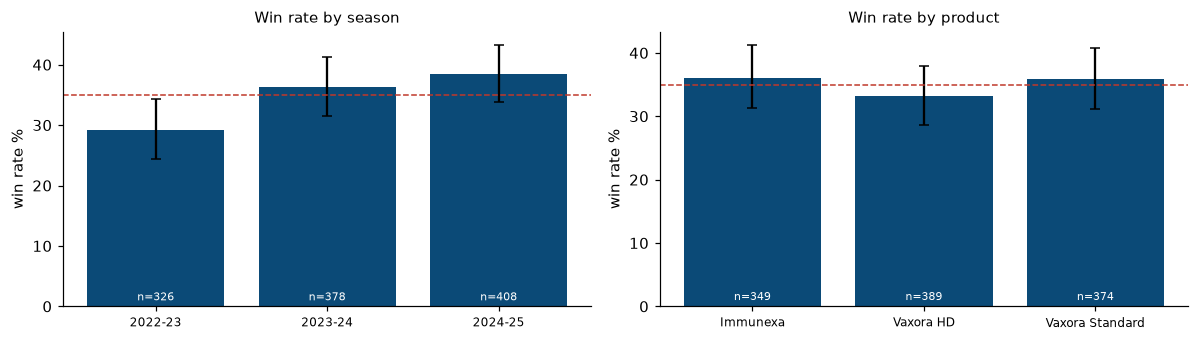

season    2022-23  2023-24  2024-25
n         326.000  378.000  408.000
win_rate    0.291    0.362    0.385
product_name  Immunexa  Vaxora HD  Vaxora Standard
n              349.000    389.000          374.000
win_rate         0.361      0.332            0.358


In [8]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
s = winrate(H, "season"); barplot(s, "Win rate by season", ax[0], base=BASE_RATE)
p = winrate(H, "product_name"); barplot(p, "Win rate by product", ax[1], base=BASE_RATE)
plt.tight_layout(); plt.show()
print(s[["n", "win_rate"]].round(3).T.to_string()); print(p[["n", "win_rate"]].round(3).T.to_string())

## 3.2 Commercial levers — does price matter?
Absolute price differs by product, so only **price relative to the competitor** is comparable.

Average price  WON: 55.14 | LOST: 55.73  (almost identical -> absolute price says nothing)


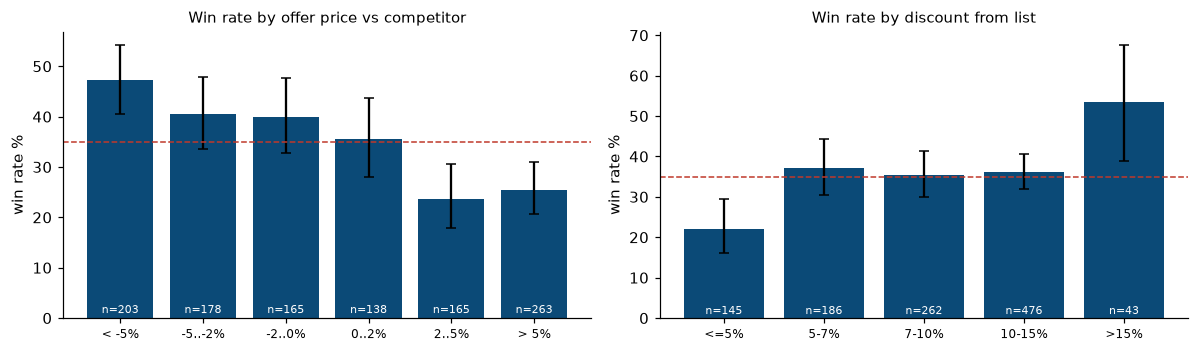

Average concession on won deals: 4.5% off the initial offer


In [9]:
print("Average price  WON: %.2f | LOST: %.2f  (almost identical -> absolute price says nothing)" %
      (H.loc[H.won==1, "initial_offered_price_per_dose"].mean(), H.loc[H.won==0, "initial_offered_price_per_dose"].mean()))
H["price_position"] = pd.cut(H["offer_vs_comp_pct"], [-100, -5, -2, 0, 2, 5, 100], labels=["< -5%", "-5..-2%", "-2..0%", "0..2%", "2..5%", "> 5%"])
H["discount_band"]  = pd.cut(H["discount_from_list"], [-100, 5, 7, 10, 15, 100], labels=["<=5%", "5-7%", "7-10%", "10-15%", ">15%"])
fig, ax = plt.subplots(1, 2, figsize=(11, 3.3))
barplot(winrate(H, "price_position"), "Win rate by offer price vs competitor", ax[0], base=BASE_RATE)
barplot(winrate(H, "discount_band"), "Win rate by discount from list", ax[1], base=BASE_RATE)
plt.tight_layout(); plt.show()
won = H[H.won == 1]
print("Average concession on won deals: %.1f%% off the initial offer" % ((1 - won.final_negotiated_price_per_dose / won.initial_offered_price_per_dose).mean() * 100))

## 3.3 Competitive context — who holds the account?

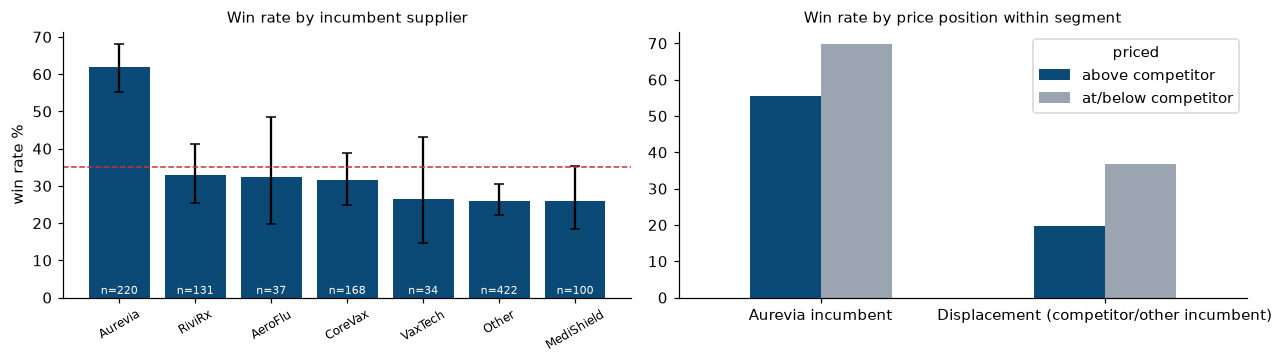

                                                      size                                 mean                    
priced                                    above competitor at/below competitor above competitor at/below competitor
segment                                                                                                            
Aurevia incumbent                                      121                  99            0.554               0.697
Displacement (competitor/other incumbent)              445                 447            0.198               0.369


In [10]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.4))
barplot(winrate(H, "incumbent_supplier").sort_values("win_rate", ascending=False), "Win rate by incumbent supplier", ax[0], base=BASE_RATE, rot=30)
H["segment"] = np.where(H.is_incumbent == 1, "Aurevia incumbent", "Displacement (competitor/other incumbent)")
H["priced"]  = np.where(H.offer_vs_comp_pct <= 0, "at/below competitor", "above competitor")
t = H.groupby(["segment", "priced"])["won"].agg(["size", "mean"]).unstack()
t["mean"].mul(100).plot.bar(ax=ax[1], color=[BLUE, GREY], rot=0); ax[1].set_title("Win rate by price position within segment", fontsize=10); ax[1].set_xlabel("")
plt.tight_layout(); plt.show(); print(t.round(3).to_string())

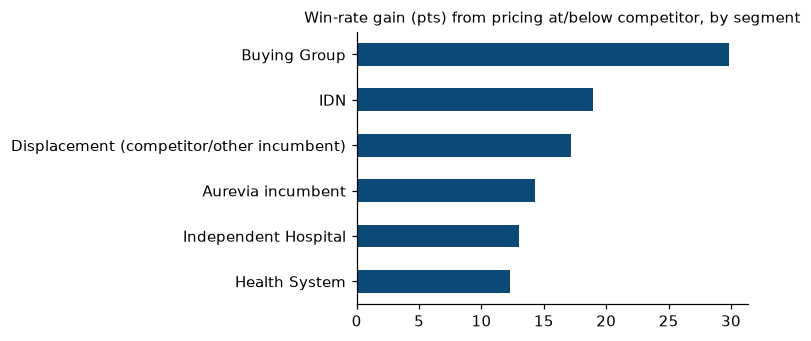

priced,above competitor,at/below competitor,lift_pts
customer_type,,,
Buying Group,0.273,0.571,29.870
Health System,0.245,0.367,12.262
IDN,0.280,0.470,18.971
Independent Hospital,0.309,0.439,13.041


In [11]:
# Price "lift" = win rate when priced at/below competitor minus win rate when priced above, by segment
def price_lift(df, by):
    t = df.groupby([by, "priced"])["won"].mean().unstack()
    t["lift_pts"] = (t["at/below competitor"] - t["above competitor"]) * 100
    return t.round(3)
lift_type, lift_inc = price_lift(H, "customer_type"), price_lift(H, "segment")
fig, ax = plt.subplots(figsize=(7, 3.2))
pd.concat([lift_type["lift_pts"], lift_inc["lift_pts"]]).sort_values().plot.barh(ax=ax, color=BLUE)
ax.set_title("Win-rate gain (pts) from pricing at/below competitor, by segment", fontsize=10); plt.tight_layout(); plt.show()
lift_type

## 3.4 Account profile — which customers are harder to win?

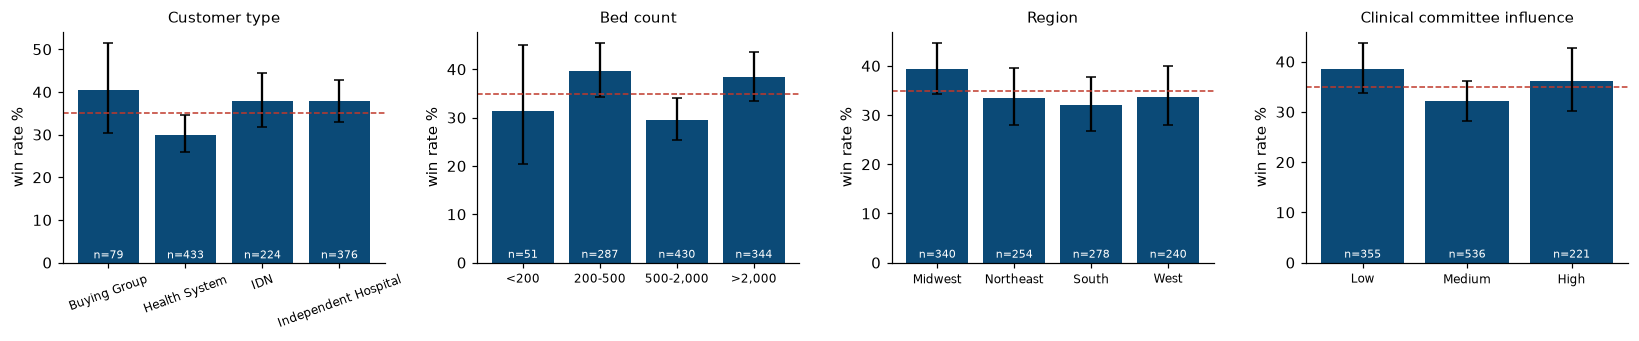

Relationship years  WON: 5.4 | LOST: 5.7


In [12]:
H["bed_band"] = pd.cut(H["bed_count"], [0, 200, 500, 2000, 1e6], labels=["<200", "200-500", "500-2,000", ">2,000"])
fig, ax = plt.subplots(1, 4, figsize=(15, 3.2))
barplot(winrate(H, "customer_type"), "Customer type", ax[0], base=BASE_RATE, rot=20)
barplot(winrate(H, "bed_band"), "Bed count", ax[1], base=BASE_RATE)
barplot(winrate(H, "region"), "Region", ax[2], base=BASE_RATE)
barplot(winrate(H, "clinical_committee_influence").loc[["Low", "Medium", "High"]], "Clinical committee influence", ax[3], base=BASE_RATE)
plt.tight_layout(); plt.show()
print("Relationship years  WON: %.1f | LOST: %.1f" % (H.loc[H.won==1, "relationship_years"].mean(), H.loc[H.won==0, "relationship_years"].mean()))

## 3.5 Engagement — does pre-offer contact matter?
Free-text notes are out of scope, so field intelligence comes only from the **structured interactions table**: how often we met the account in the 12 months *before* the offer, whether issues were raised, and whether the clinical committee was engaged.

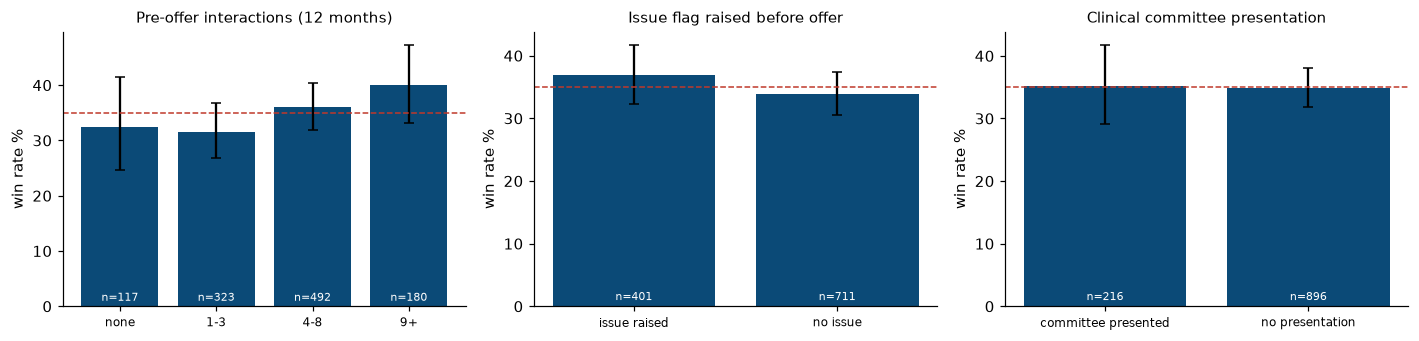

Deals with any pre-offer interaction on record: 89%
season                        2022-23  2023-24  2024-25
share with pre-offer contact     0.65     0.99      1.0
Early seasons have little prior history (cold start) -> contact coverage must be monitored, and a 'no contact' flag is built.


In [13]:
def in_window(m, date_col="interaction_date"):
    # events strictly BEFORE the offer date and within the look-back window
    return (m[date_col] < m["offer_date"]) & (m[date_col] >= m["offer_date"] - pd.Timedelta(days=WINDOW_DAYS))

mi = H[["opportunity_id", "customer_id", "offer_date"]].merge(interactions, on="customer_id"); mi = mi[in_window(mi)]
g = mi.groupby("opportunity_id")
E = pd.DataFrame({"n": g.size(), "issues": g["issue_flag_raised"].sum(),
                  "committee": g["interaction_type"].apply(lambda s: (s == "clinical_committee_presentation").sum())})
HE = H.merge(E, left_on="opportunity_id", right_index=True, how="left").fillna({"n": 0, "issues": 0, "committee": 0})
HE["contact_band"]   = pd.cut(HE["n"], [-1, 0, 3, 8, 1000], labels=["none", "1-3", "4-8", "9+"])
HE["issue_raised"]   = np.where(HE["issues"] > 0, "issue raised", "no issue")
HE["committee_pres"] = np.where(HE["committee"] > 0, "committee presented", "no presentation")
fig, ax = plt.subplots(1, 3, figsize=(13, 3.2))
barplot(winrate(HE, "contact_band"), "Pre-offer interactions (12 months)", ax[0], base=BASE_RATE)
barplot(winrate(HE, "issue_raised"), "Issue flag raised before offer", ax[1], base=BASE_RATE)
barplot(winrate(HE, "committee_pres"), "Clinical committee presentation", ax[2], base=BASE_RATE)
plt.tight_layout(); plt.show()
print(f"Deals with any pre-offer interaction on record: {(HE['n'] > 0).mean():.0%}")
print(HE.assign(has_contact=HE["n"] > 0).groupby("season")["has_contact"].mean().round(2).rename("share with pre-offer contact").to_frame().T.to_string())
print("Early seasons have little prior history (cold start) -> contact coverage must be monitored, and a 'no contact' flag is built.")

## 3.6 Process timing — which signals only *look* predictive?

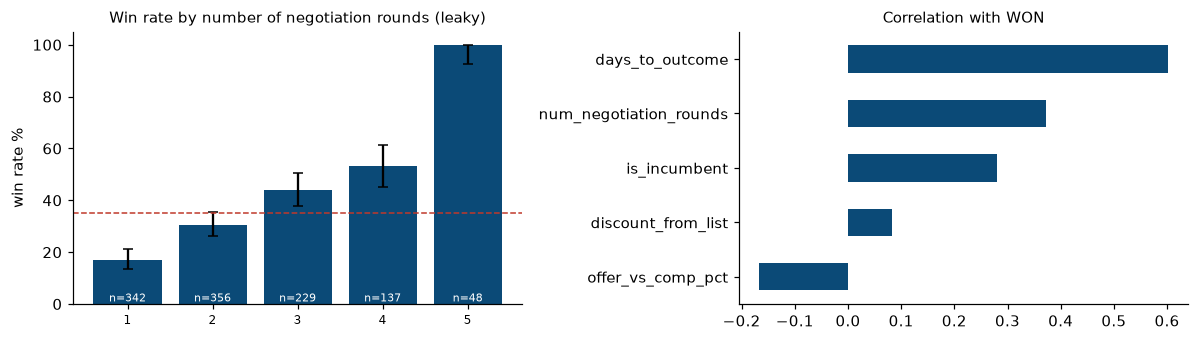

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
barplot(winrate(H, "num_negotiation_rounds"), "Win rate by number of negotiation rounds (leaky)", ax[0], base=BASE_RATE)
H["days_to_outcome"] = (H["outcome_date"] - H["offer_date"]).dt.days
H["final_price_present"] = H["final_negotiated_price_per_dose"].notna().astype(int)
num = H[["won", "days_to_outcome", "num_negotiation_rounds", "offer_vs_comp_pct", "is_incumbent", "discount_from_list"]]
num.corr()["won"].drop("won").sort_values().plot.barh(ax=ax[1], color=BLUE); ax[1].set_title("Correlation with WON", fontsize=10)
plt.tight_layout(); plt.show()

In [15]:
# How much would leakage inflate performance?  Same model, with vs without post-offer signals (train 2022-24, test 2024-25)
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score
clean_cols = ["offer_vs_comp_pct", "discount_from_list", "is_incumbent", "bed_count", "relationship_years", "clin_ord", "has_buying_group"]
H["clin_ord"] = H["clinical_committee_influence"].map({"Low": 0, "Medium": 1, "High": 2}); H["has_buying_group"] = H["buying_group_id"].notna().astype(int)
X = pd.get_dummies(H[clean_cols + ["customer_type", "product_id"]], drop_first=True).astype(float)
leaky = X.assign(num_rounds=H.num_negotiation_rounds, days_to_outcome=H.days_to_outcome)    # negotiation-stage signals
# (the final price is even worse: its mere presence IS the outcome, so it is excluded without testing)
tr, te = (H.season != HOLDOUT).values, (H.season == HOLDOUT).values
for name, XX in [("only offer-time information", X), ("+ post-offer signals (LEAKY)", leaky)]:
    mdl = HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05, max_iter=150, random_state=0).fit(XX[tr], H.won[tr])
    print(f"{name:32s} AUC on unseen season = {roc_auc_score(H.won[te], mdl.predict_proba(XX[te])[:, 1]):.3f}")
print("\nThe lower number is the honest one — it is what users will see in production.")

only offer-time information      AUC on unseen season = 0.672
+ post-offer signals (LEAKY)     AUC on unseen season = 0.929

The lower number is the honest one — it is what users will see in production.


## 3.7 Overlaps — which signals say the same thing?

In [16]:
print("corr(bed_count, annual_flu_doses_est)       = %.2f  -> keep one" % H["bed_count"].corr(H["annual_flu_doses_est"]))
print("prior_year_volume > 0  <=>  Aurevia incumbent: %s" % bool(((H.prior_year_volume > 0) == (H.is_incumbent == 1)).all()))
print("\nCustomer-type mix by size band (size and type overlap):")
pd.crosstab(H["bed_band"], H["customer_type"], normalize="index").round(2)

corr(bed_count, annual_flu_doses_est)       = 0.93  -> keep one
prior_year_volume > 0  <=>  Aurevia incumbent: True

Customer-type mix by size band (size and type overlap):


customer_type,Buying Group,Health System,IDN,Independent Hospital
bed_band,,,,
<200,0.00,0.00,0.00,1.00
200-500,0.00,0.00,0.00,1.00
"500-2,000",0.00,0.91,0.00,0.09
">2,000",0.23,0.12,0.65,0.00


# Part 4 — Feature identification and selection  (walkthrough §4)
## 4.1 Candidate features from the EDA
| Business question | EDA finding | Candidate features |
|---|---|---|
| Are we priced to win? | Win rate falls above competitor price | price vs competitor %, discount from list % |
| Do we hold the account? | Incumbents win far more | Aurevia incumbent, prior-year volume, competitor |
| What kind of buyer? | Buying groups price-driven, health systems not | customer type, size, region, buying group |
| How engaged are they? | Pre-offer contact varies | pre-offer meetings, issue flags, committee presentations, days since last contact |
| Does price matter more for some? | Price lift differs by segment | price × incumbent, price × customer type |

## 4.2 Selection funnel — steps 1 to 4 (step 5, "confirmed by the model", happens in Notebook 2)
| Step | Rule | Removed |
|---|---|---|
| 1 Available at offer time | known on offer date and present for 2025-26 | `num_negotiation_rounds`, `days_to_outcome`, `final_negotiated_price`, `outcome_date`, decks, rounds file, post-offer interactions |
| 2 Usable and lawful | no names; ids only for joining | customer name, `rep_id`, `state`, `buying_group_id`; call notes & decks (out of scope) |
| 3 Not redundant | drop one of each overlapping pair | `annual_flu_doses_est` (keep beds), prior-volume *flag* (== incumbency) |
| 4 Business signal | visible in EDA or clear rationale | tenure & clinical influence kept as *candidates* only |

In [17]:
LEAKY    = ["final_negotiated_price_per_dose", "num_negotiation_rounds", "outcome_date", "outcome", "days_to_outcome"]   # step 1
NOT_USED = ["customer_name", "state", "buying_group_id", "annual_flu_doses_est"]                                       # steps 2-3
print("Hard-blocked (step 1):", LEAKY); print("Dropped (steps 2-3):", NOT_USED)

Hard-blocked (step 1): ['final_negotiated_price_per_dose', 'num_negotiation_rounds', 'outcome_date', 'outcome', 'days_to_outcome']
Dropped (steps 2-3): ['customer_name', 'state', 'buying_group_id', 'annual_flu_doses_est']


# Part 5 — Data preparation  (walkthrough §5)
## 5.1–5.2 Construct features (all **as of the offer date**)
* **Price:** `price_vs_comp_pct = offer / competitor − 1`, `discount_from_list_pct = 1 − offer / list` (same scale for all 3 products).
* **Engagement:** counts from the 12 months before the offer. No contact → 0 **plus** a `no_contact` flag.
* **Interactions:** price × incumbent, price × customer type.
* **History (extra candidate, tested in Notebook 2):** the customer's results in *previous seasons only*. Same-season outcomes are excluded because they do not exist yet when 2025-26 is scored.

In [18]:
def add_price_features(d, move=0.0):
    # price features from raw prices; `move` lets the simulator re-price an offer by e.g. -0.05. Used again in Notebook 2.
    offer = d["initial_offered_price_per_dose"] * (1 + move)
    d = d.copy()
    d["price_vs_comp_pct"]      = (offer / d["competitor_price_estimate_per_dose"] - 1) * 100
    d["discount_from_list_pct"] = (1 - offer / d["list_price_per_dose"]) * 100
    d["price_x_incumbent"]      = d["price_vs_comp_pct"] * d["is_incumbent"]
    for t in ["Health System", "Independent Hospital", "IDN", "Buying Group"]:
        d["price_x_type_" + t.replace(" ", "_")] = d["price_vs_comp_pct"] * (d["customer_type"] == t)
    return d

# ---- static / account / product ----
df = opps.merge(customers.drop(columns=["customer_name", "state", "buying_group_id", "annual_flu_doses_est", "clinical_committee_influence"]), on="customer_id", how="left")
df = df.merge(products[["product_id", "product_name", "list_price_per_dose"]], on="product_id", how="left")
df["is_incumbent"] = (df["incumbent_supplier"] == "Aurevia").astype(int)
df["comp_family"]  = df["competitor_product"].str.split().str[0]
df["log_prior_volume"] = np.log1p(df["prior_year_volume"])
df["log_beds"] = np.log(df["bed_count"])
df = add_price_features(df)

# ---- engagement (all interactions of the account in the 12 months before the offer) ----
keys = df[["opportunity_id", "customer_id", "product_id", "offer_date", "season_year", "competitor_product"]]
m = keys.merge(interactions, on="customer_id")
m = m[in_window(m)].copy()
m["days_before"] = (m.offer_date - m.interaction_date).dt.days
g = m.groupby("opportunity_id")
eng = pd.DataFrame({"eng_n_interactions": g.size(), "eng_n_recent": g["days_before"].apply(lambda s: (s <= RECENT_DAYS).sum()),
                    "eng_n_issue_flags": g["issue_flag_raised"].sum(),
                    "eng_n_clin_committee": g["interaction_type"].apply(lambda s: (s == "clinical_committee_presentation").sum()),
                    "eng_days_since_contact": g["days_before"].min()})

# ---- customer history: PREVIOUS SEASONS only ----
prev = df.loc[df.dataset == "history", ["customer_id", "season_year", "outcome_date", "target"]].rename(columns={"season_year": "p_year", "outcome_date": "p_out", "target": "p_win"})
m = keys.merge(prev, on="customer_id"); m = m[(m.p_year < m.season_year) & (m.p_out < m.offer_date)].sort_values("p_out")
g = m.groupby("opportunity_id")
hs = pd.DataFrame({"hist_n_prior": g.size(), "hist_wins": g["p_win"].sum(), "hist_last_outcome": g["p_win"].last()})

# ---- assemble ----
for part in (eng, hs): df = df.merge(part, left_on="opportunity_id", right_index=True, how="left")
df.shape

(1542, 44)

## 5.1 Imputation (documented, never silent)
| Field | Rule |
|---|---|
| Buying group blank | `has_buying_group = 0` ("none") |
| No pre-offer contact | counts = 0, `eng_no_contact = 1`; `eng_days_since_contact` left missing → imputed with the training median inside the model pipeline |
| History empty (first season / new account) | counts = 0, win-rate = smoothing prior |
| Final price | never imputed (excluded) |

In [19]:
count_cols = [c for c in df if c.startswith(("eng_n_", "hist_n", "hist_wins"))]
df[count_cols] = df[count_cols].fillna(0)
df["eng_no_contact"] = (df["eng_n_interactions"] == 0).astype(int)
PRIOR_RATE, PRIOR_W = 0.35, 2.0                      # business prior to smooth tiny histories
df["hist_win_rate_prior"] = (df["hist_wins"] + PRIOR_W * PRIOR_RATE) / (df["hist_n_prior"] + PRIOR_W)

print("Coverage by season (note the cold start in the first season — it matters for monitoring):")
df.groupby("season")[["eng_no_contact"]].mean().round(3).rename(columns=lambda c: c + " share")

Coverage by season (note the cold start in the first season — it matters for monitoring):


,eng_no_contact share
season,
2022-23,0.350
2023-24,0.005
2024-25,0.002
2025-26,0.002


## 5.3 Standardise & save
* One table per deal, **identical layout for history and 2025-26**, fixed column types.
* Scaling is deliberately **not** done here: it is fitted on training data only, inside the model pipeline (Notebook 2).
* Raw prices are kept as `sim_*` columns purely so the what-if simulator can re-price an offer; they are not model inputs.

In [20]:
FEATURE_GROUPS = {
 "price":        ["price_vs_comp_pct", "discount_from_list_pct"],
 "competition":  ["is_incumbent", "comp_family", "log_prior_volume"],
 "account":      ["customer_type", "log_beds", "region", "has_buying_group", "relationship_years", "clin_ord"],
 "product":      ["product_id"],
 "engagement":   ["eng_n_interactions", "eng_n_issue_flags", "eng_n_clin_committee", "eng_days_since_contact", "eng_no_contact"],
 "interactions": ["price_x_incumbent"] + [c for c in df if c.startswith("price_x_type_")],
 "history":      ["hist_n_prior", "hist_win_rate_prior", "hist_last_outcome"],
}
META = ["opportunity_id", "customer_id", "customer_name", "product_name", "incumbent_supplier", "season", "offer_date", "dataset", "target"]
SIM  = {"initial_offered_price_per_dose": "sim_offer_price", "competitor_price_estimate_per_dose": "sim_comp_price", "list_price_per_dose": "sim_list_price"}

feats = [c for g in FEATURE_GROUPS.values() for c in g]
assert not set(feats) & set(LEAKY), "leaky column in feature list"
assert len(feats) == len(set(feats))
model_table = (df.merge(customers[["customer_id", "customer_name"]], on="customer_id", how="left")
                 .rename(columns=SIM)[META + list(SIM.values()) + feats])
model_table.to_csv(PROCESSED_DIR + "model_table.csv", index=False)
pd.Series({k: len(v) for k, v in FEATURE_GROUPS.items()}, name="n_features").to_frame().T

,price,competition,account,product,engagement,interactions,history
n_features,2,3,6,1,5,5,3


In [21]:
# Redundancy check on the final numeric features
numf = model_table.loc[model_table.dataset == "history", [c for c in feats if pd.api.types.is_numeric_dtype(model_table[c])]]
cm = numf.corr().abs().where(np.triu(np.ones((numf.shape[1],) * 2), 1).astype(bool)).stack().sort_values(ascending=False)
print("Highly correlated pairs (|r| > 0.85):"); print(cm[cm > 0.85].round(2).to_string() or "none")
print("\nSaved:", PROCESSED_DIR + "model_table.csv", model_table.shape, "| history rows:", (model_table.dataset == "history").sum(), "| 2025-26 rows:", (model_table.dataset == "score").sum())

Highly correlated pairs (|r| > 0.85):
is_incumbent         log_prior_volume     0.98
hist_win_rate_prior  hist_last_outcome    0.87

Saved: ../data/processed/model_table.csv (1542, 37) | history rows: 1112 | 2025-26 rows: 430


## Optional — automated EDA report (Sweetviz)
Run if installed (`%pip install sweetviz`). The report opens from the JupyterLab file browser.

In [22]:
try:
    import sweetviz as sv, io, contextlib
    hist_tbl = model_table[model_table.dataset == "history"][feats + ["target"]].copy(); hist_tbl["target"] = hist_tbl["target"].astype(int)
    cat = [c for c in feats if not pd.api.types.is_numeric_dtype(hist_tbl[c])]
    with contextlib.redirect_stdout(io.StringIO()), contextlib.redirect_stderr(io.StringIO()):
        rep = sv.analyze(hist_tbl, target_feat="target", pairwise_analysis="off",
                         feat_cfg=sv.FeatureConfig(force_num=[c for c in feats if c not in cat], force_cat=cat))
        rep.show_html(PROCESSED_DIR + "eda_model_table_sweetviz.html", open_browser=False)
    print("Sweetviz report saved to", PROCESSED_DIR + "eda_model_table_sweetviz.html")
except Exception as e:
    print("Sweetviz skipped:", e)

Sweetviz skipped: No module named 'sweetviz'


## Hand-off to Notebook 2
`data/processed/model_table.csv` is ready. Notebook 2 performs funnel step 5 (keep only features that help on an unseen season), compares models, selects the best one, calibrates it, explains it, and builds the price what-if simulator.